# Classification Track — Adult Census Income Prediction
### 23CSE301 Machine Learning Capstone — Review 1 (Part A) + Review 2 (Part B)

**Dataset:** UCI Adult / Census Income dataset (`adult.data` + `adult.test` merged) — 48,842 records of U.S. census respondents.

**Goal:** Predict whether a person's annual income exceeds $50K (`income`: `<=50K` / `>50K`) from demographic and employment features.

**Scope:**
- **Part A (Review 1):** Logistic Regression, KNN, Naive Bayes, Decision Tree, SVM — Sections A–D.
- **Part B (Review 2):** Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP — Section E, trained on the *same* split and the
  *same* preprocessing as Part A.
- **Review 2 deliverables:** the consolidated 10-algorithm comparison table (Section F), final model selection with
  hyperparameter tuning (Section G) and the exported model used by the web app (Section H).

All random operations use `random_state=42` for reproducibility.

In [1]:
import warnings
import time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Shared infrastructure used across every algorithm below (splitting, preprocessing, tuning, scoring).
# Each individual algorithm's own class is imported right where that algorithm is used, not here.
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100

## Section A — Dataset Loading & Exploratory Data Analysis

### A1. Dataset Loading & Audit

**Note on missing values:** the raw UCI Adult files mark missing entries with the literal string `?` rather than leaving the
field blank. `na_values=['?']` tells `pandas` to parse those cells as genuine `NaN` on load, so `.isna().sum()` below correctly reports
them as missing instead of silently treating `"?"` as a valid category value.

In [2]:
df = pd.read_csv('../data/adult.csv', na_values=['?'])
print("Shape:", df.shape)
df.head()

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("Data types:\n")
print(df.dtypes)
print("\nMissing values per column:\n")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Data types:

age               int64
workclass           str
fnlwgt            int64
education           str
education-num     int64
marital-status      str
occupation          str
relationship        str
race                str
sex                 str
capital-gain      int64
capital-loss      int64
hours-per-week    int64
native-country      str
income              str
dtype: object

Missing values per column:

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

Duplicate rows: 52


In [4]:
print("Target ('income') class distribution:\n")
print(df['income'].value_counts())
print()
print(df['income'].value_counts(normalize=True).round(4))

Target ('income') class distribution:

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

income
<=50K    0.7607
>50K     0.2393
Name: proportion, dtype: float64


**Observation:** 48,842 rows, 15 columns. Three categorical columns (`workclass`, `occupation`, `native-country`) contain missing
values (originally encoded as `?` in the raw files) — around 5–6% of rows are affected. There are 52 exact duplicate rows. The target is
**imbalanced**: ~76% earn `<=50K` vs. ~24% earn `>50K`, which is why we use a **stratified** train/test split and report **weighted** F1/
Precision/Recall (accuracy alone would be misleading on an imbalanced target).

### A2. EDA Visualisations

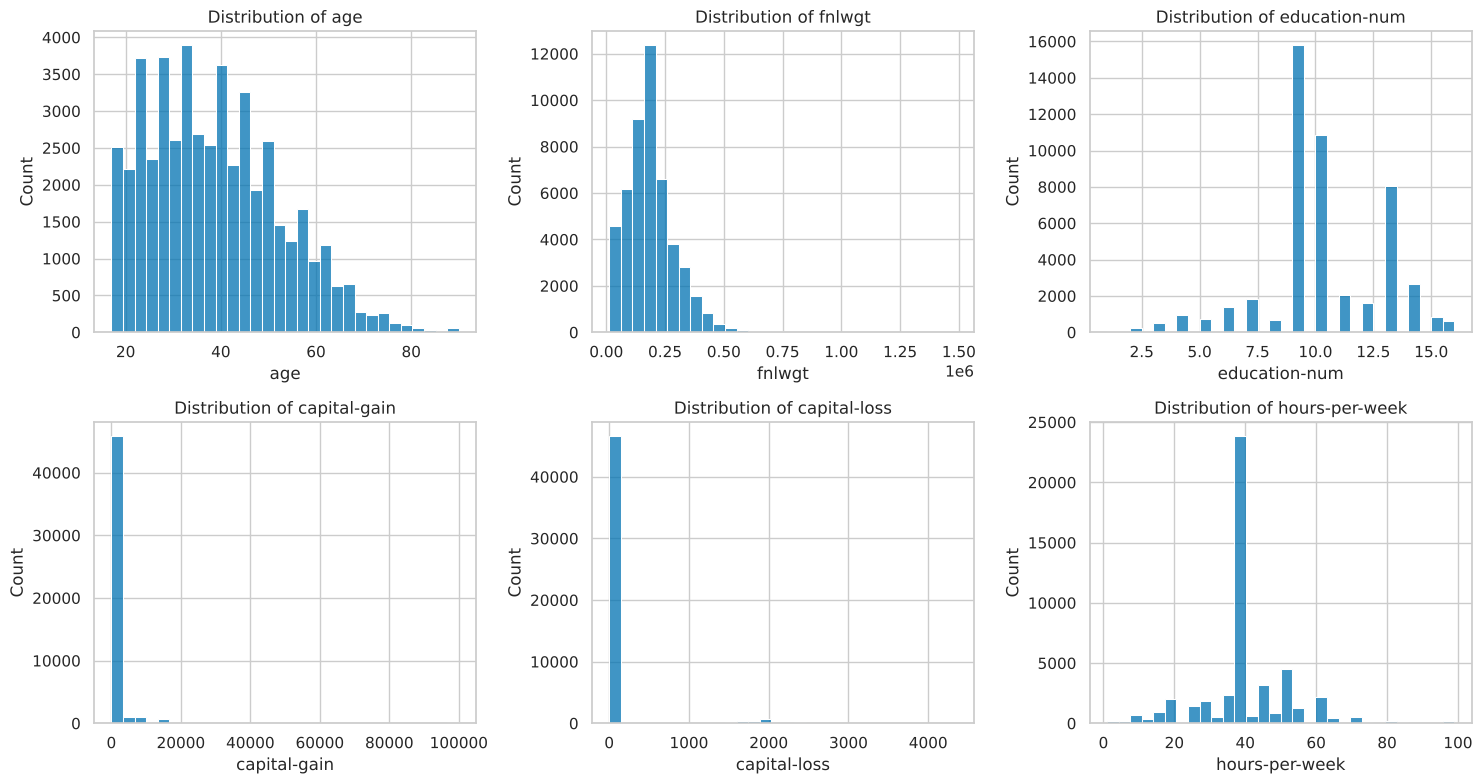

In [5]:
numeric_dist_cols = ['age','fnlwgt','education-num','capital-gain','capital-loss','hours-per-week']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, col in enumerate(numeric_dist_cols):
    sns.histplot(df[col], bins=30, ax=axes[i], color='#0072B2')
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig('clf_feature_distributions.png', bbox_inches='tight')
plt.show()

**Insight:** `capital-gain` and `capital-loss` are extremely sparse (mostly 0, with a long tail of large values) — most respondents
report no capital gains/losses at all. `age` is right-skewed towards younger adults. `hours-per-week` is heavily concentrated at 40
(standard full-time week) with some outliers near 0 and near 99.

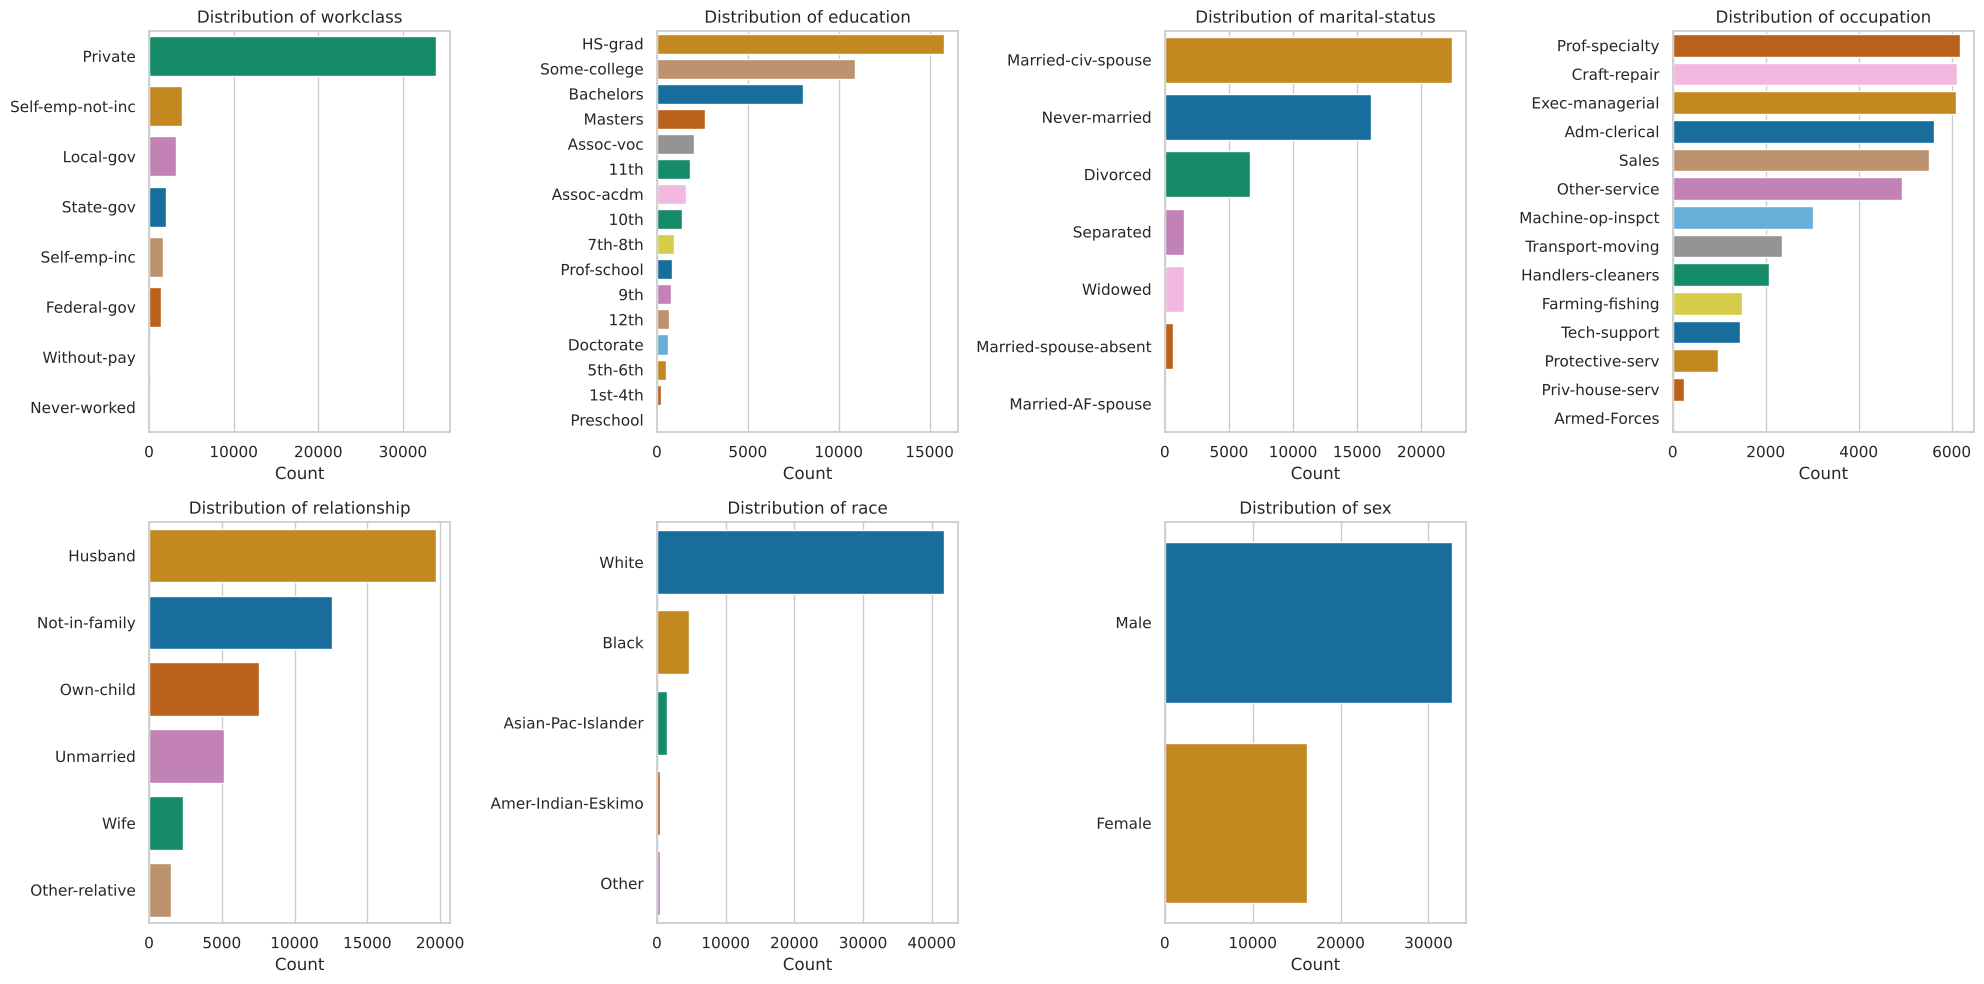

In [6]:
categorical_dist_cols = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex']
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()
for i, col in enumerate(categorical_dist_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, hue=col, palette='colorblind', legend=False, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Count'); axes[i].set_ylabel('')
axes[-1].axis('off')  # unused 8th slot
plt.tight_layout()
plt.savefig('clf_categorical_distributions.png', bbox_inches='tight')
plt.show()

**Insight:** `workclass` and `occupation` are dominated by `Private`/a handful of common occupations, `education` peaks at
`HS-grad` and `Some-college`, `marital-status` is bimodal (Never-married vs. Married-civ-spouse), and `sex`/`race` are both heavily
imbalanced (more male, more White respondents) — a reminder that any fairness-sensitive conclusions from this dataset should be read
with that skew in mind.

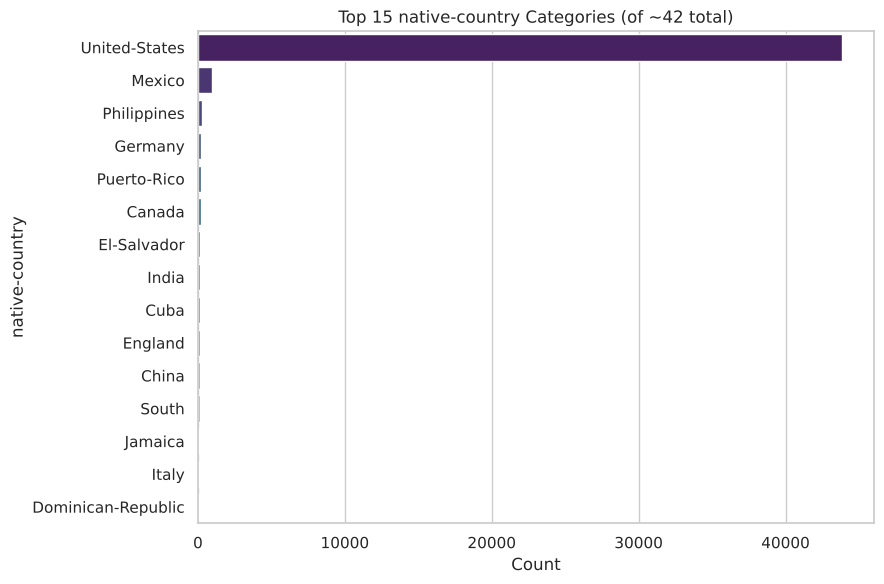

In [7]:
top_countries = df['native-country'].value_counts().head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, palette='viridis', legend=False)
plt.title('Top 15 native-country Categories (of ~42 total)')
plt.xlabel('Count'); plt.ylabel('native-country')
plt.tight_layout()
plt.savefig('clf_native_country_distribution.png', bbox_inches='tight')
plt.show()

**Insight:** `native-country` is extremely dominated by `United-States` (~90% of records); the ~40 remaining countries are shown
as a horizontal bar of the top 15 because a standard vertical/pie chart across all ~42 categories would be unreadable. This extreme
imbalance is also why the OneHotEncoder later uses `handle_unknown='ignore'` — a rare country seen only in the test split should not
break the pipeline.

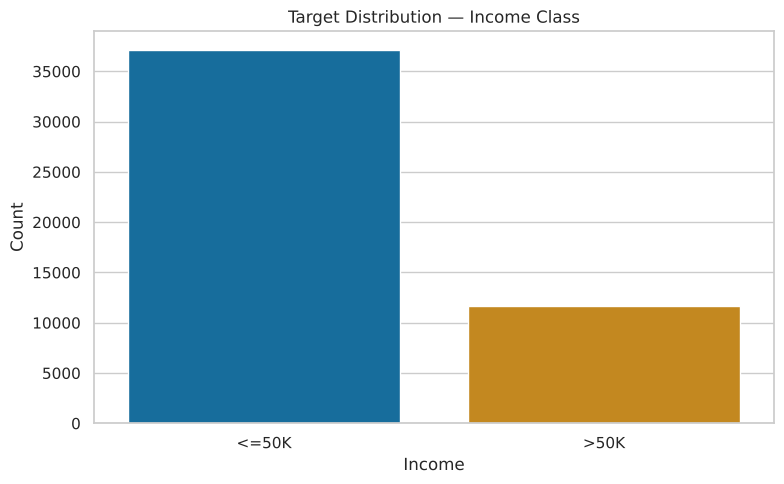

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='income', hue='income', palette='colorblind', legend=False)
plt.title('Target Distribution — Income Class')
plt.xlabel('Income'); plt.ylabel('Count')
plt.tight_layout()
plt.savefig('clf_target_distribution.png', bbox_inches='tight')
plt.show()

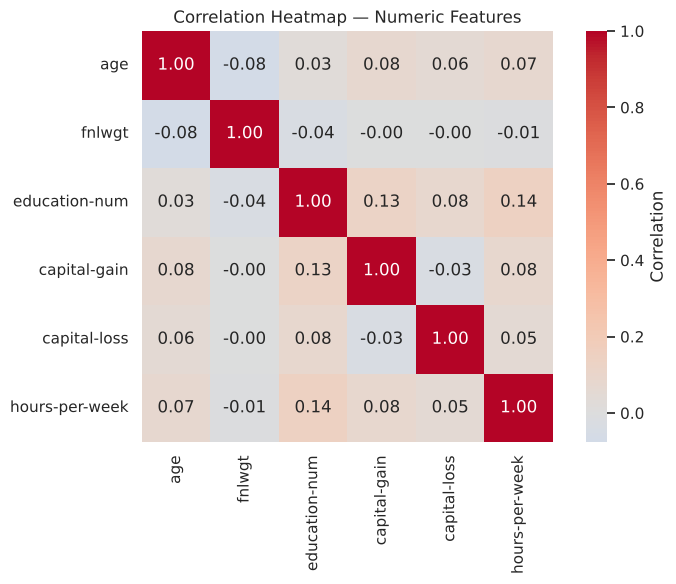

In [9]:
plt.figure(figsize=(8, 6))
corr = df[numeric_dist_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar_kws={'label':'Correlation'})
plt.title('Correlation Heatmap — Numeric Features')
plt.tight_layout()
plt.savefig('clf_correlation_heatmap.png', bbox_inches='tight')
plt.show()

**Insight:** Numeric features are only weakly correlated with each other (no strong multicollinearity issue), meaning most of the
predictive signal for income will need to come from the categorical features (occupation, marital-status, education) rather than a couple
of dominant numeric predictors.

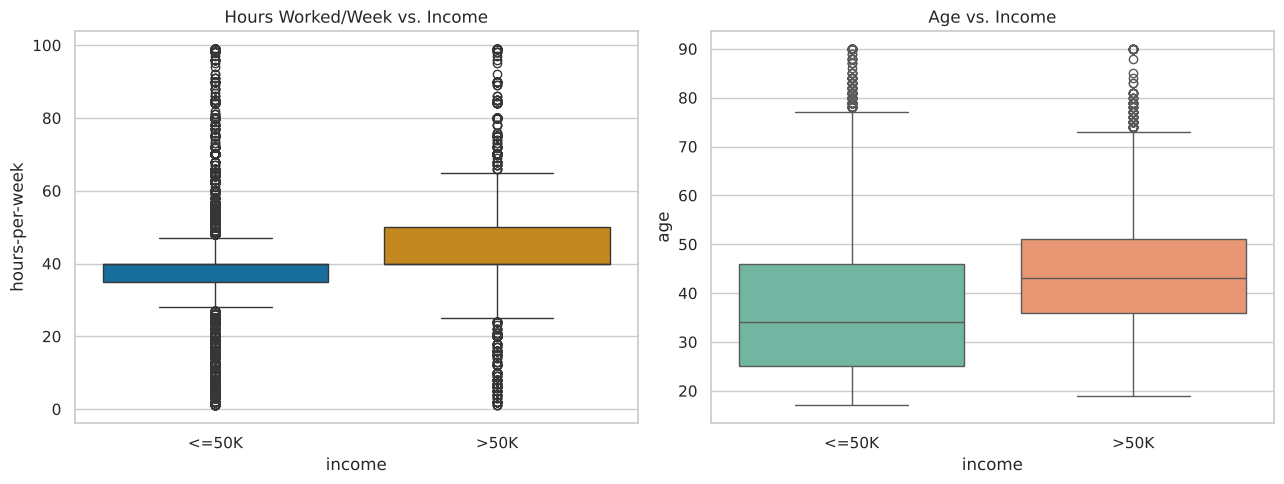

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x='income', y='hours-per-week', hue='income', palette='colorblind', ax=axes[0], legend=False)
axes[0].set_title('Hours Worked/Week vs. Income')

sns.boxplot(data=df, x='income', y='age', hue='income', palette='Set2', ax=axes[1], legend=False)
axes[1].set_title('Age vs. Income')
plt.tight_layout()
plt.savefig('clf_boxplot_feature_target.png', bbox_inches='tight')
plt.show()

**Insight:** Both `hours-per-week` and `age` are visibly higher on average for the `>50K` group — high earners tend to work more
hours and be somewhat older (peak earning years), giving these two numeric features real discriminative power despite their weak pairwise
correlations seen above. The scatter plots below show the same two relationships as literal x-y scatter plots.

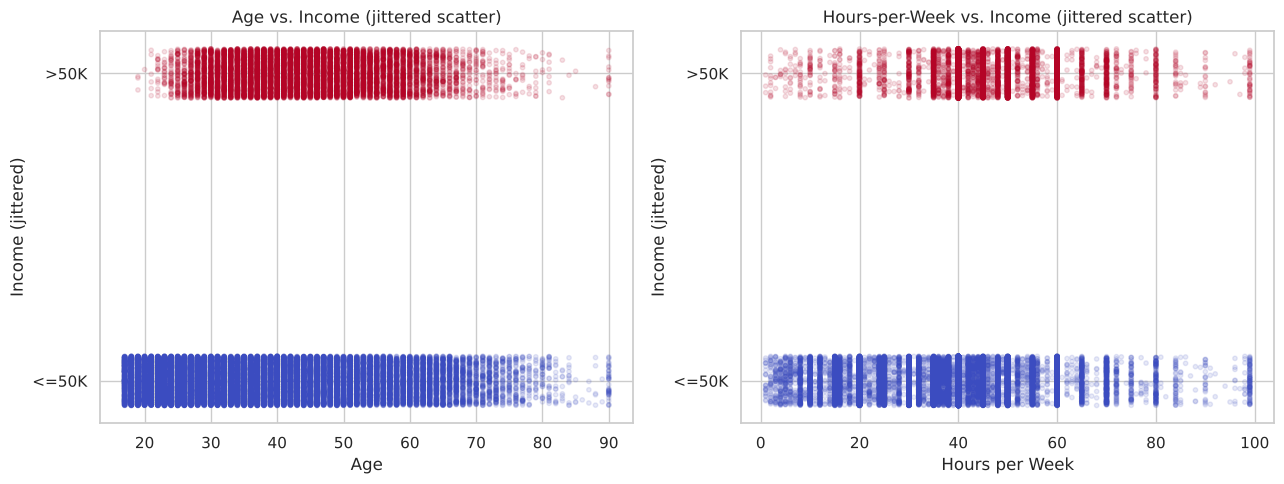

In [11]:
# income is binary, so a plain scatter against it would collapse into two flat lines at y=0 and y=1.
# A small uniform jitter on the (numeric) target reveals point density while keeping both axes genuinely numeric/continuous.
rng = np.random.RandomState(RANDOM_STATE)
income_numeric = (df['income'] == '>50K').astype(int)
jitter = rng.uniform(-0.08, 0.08, size=len(df))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(df['age'], income_numeric + jitter, alpha=0.12, s=10, c=income_numeric, cmap='coolwarm')
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(['<=50K', '>50K'])
axes[0].set_xlabel('Age'); axes[0].set_ylabel('Income (jittered)')
axes[0].set_title('Age vs. Income (jittered scatter)')

axes[1].scatter(df['hours-per-week'], income_numeric + jitter, alpha=0.12, s=10, c=income_numeric, cmap='coolwarm')
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(['<=50K', '>50K'])
axes[1].set_xlabel('Hours per Week'); axes[1].set_ylabel('Income (jittered)')
axes[1].set_title('Hours-per-Week vs. Income (jittered scatter)')
plt.tight_layout()
plt.savefig('clf_scatter_feature_target.png', bbox_inches='tight')
plt.show()

**Insight:** Jittering the binary target turns an otherwise-uninformative two-line plot into a readable density picture: the
`>50K` band (top) is visibly thinner and shifted toward older ages and 40+ hour weeks, while the `<=50K` band (bottom) is denser at
younger ages and spread across both shorter and standard work weeks — the same pattern the boxplots above show, now as a literal
feature-vs-target scatter plot.

## Section B — Data Cleaning, Encoding & Feature Engineering

### B1. Data Cleaning

In [12]:
df_clean = df.drop_duplicates().copy()
print(f"Dropped {df.duplicated().sum()} duplicates -> shape: {df_clean.shape}")

# 'education' is a redundant text version of the already-numeric ordinal 'education-num' -> drop to avoid
# redundant/duplicated information going into one-hot encoding.
# 'fnlwgt' is a census sampling weight (not a demographic/economic attribute of the person) -> not predictive, drop.
df_clean = df_clean.drop(columns=['education', 'fnlwgt'])

print("Missing-value strategy: 'workclass', 'occupation', 'native-country' missing values are imputed with the "
      "column mode (most frequent category), fitted on the TRAINING split only (see ColumnTransformer below) "
      "-- this avoids discarding ~5-6% of rows while keeping the imputation leakage-free.")

Dropped 52 duplicates -> shape: (48790, 15)
Missing-value strategy: 'workclass', 'occupation', 'native-country' missing values are imputed with the column mode (most frequent category), fitted on the TRAINING split only (see ColumnTransformer below) -- this avoids discarding ~5-6% of rows while keeping the imputation leakage-free.


**Outlier check:** `hours-per-week` has a small number of extreme values (near 0 and near 99) that are legitimate but very rare.
We clip them to the 1st/99th percentile **computed on the training set only** (after the split, below) rather than deleting rows, so
extreme-but-real cases are retained in a bounded form instead of distorting the scaler.

### B2. Feature Engineering

In [13]:
# capital-gain and capital-loss are both extremely sparse (mostly zero) and never both non-zero for the same person.
# Combining them into a single net signal reduces sparsity and gives the model one informative numeric feature
# instead of two mostly-zero ones.
df_clean['capital_net'] = df_clean['capital-gain'] - df_clean['capital-loss']
df_clean[['capital-gain','capital-loss','capital_net']].describe()

,capital-gain,capital-loss,capital_net
count,48790.000000,48790.000000,48790.000000
mean,1080.217688,87.595573,992.622115
std,7455.905921,403.209129,7479.462491
min,0.000000,0.000000,-4356.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,99999.000000,4356.000000,99999.000000


### B3. Encoding, Scaling & Stratified Train/Test Split

In [14]:
TARGET = 'income'
NUMERIC_COLS = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'capital_net']
CATEGORICAL_COLS = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

y = (df_clean[TARGET] == '>50K').astype(int)
X = df_clean.drop(columns=[TARGET])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Train class balance:\n", y_train.value_counts(normalize=True).round(4))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(4))

# Outlier clipping bounds computed on TRAIN ONLY, then applied to both splits (no leakage)
lo, hi = X_train['hours-per-week'].quantile([0.01, 0.99])
X_train['hours-per-week'] = X_train['hours-per-week'].clip(lo, hi)
X_test['hours-per-week'] = X_test['hours-per-week'].clip(lo, hi)
print(f"\n'hours-per-week' clipped to [{lo}, {hi}] using train-set percentiles")

# Each model below gets its OWN fresh preprocessor via this factory function rather than sharing one
# ColumnTransformer instance. A ColumnTransformer is a MUTABLE object: if the same instance were reused
# across multiple Pipelines, calling .fit() for model B would silently re-fit (overwrite) the imputer/
# encoder/scaler that model A's already-fitted Pipeline still points to (Python passes objects by reference).
# This matters concretely here because SVC (below) is deliberately fit on a smaller stratified SUBSAMPLE
# of the training data -- if it shared a preprocessor with the other four models, fitting SVC would quietly
# swap those models' fitted encoder/scaler statistics out from under them. make_preprocessor() prevents that
# by constructing a brand-new, independent ColumnTransformer every time it's called.
def make_preprocessor():
    return ColumnTransformer([
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
        ]), CATEGORICAL_COLS),
        ('num', StandardScaler(), NUMERIC_COLS)
    ])

Train: (39032, 13), Test: (9758, 13)
Train class balance:
 income
0    0.7606
1    0.2394
Name: proportion, dtype: float64
Test class balance:
 income
0    0.7606
1    0.2394
Name: proportion, dtype: float64

'hours-per-week' clipped to [8.0, 80.0] using train-set percentiles


**Leakage prevention:** the imputer, one-hot encoder and scaler all live inside the `ColumnTransformer` returned by
`make_preprocessor()`, itself nested inside each model's `Pipeline`. Calling `pipeline.fit(X_train, y_train)` fits every preprocessing
step using training-set statistics only; `predict(X_test)` only ever calls `.transform()`. Stratified splitting preserves the ~76/24
class ratio in both train and test.

## Section C — Classification Track, Part A: 5 Algorithms

In [15]:
results = []
fitted_models = {}

def run_model(name, pipeline, Xtr=X_train, ytr=y_train):
    t0 = time.perf_counter()
    pipeline.fit(Xtr, ytr)
    train_time = time.perf_counter() - t0          # wall-clock fit time (Review 2 addition, used in the trade-off discussion)
    preds = pipeline.predict(X_test)
    try:
        proba = pipeline.predict_proba(X_test)[:, 1]
    except AttributeError:
        proba = pipeline.decision_function(X_test)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='weighted')
    prec = precision_score(y_test, preds, average='weighted')
    rec = recall_score(y_test, preds, average='weighted')
    auc = roc_auc_score(y_test, proba)
    cm = confusion_matrix(y_test, preds)
    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec,
                     'F1 (weighted)': f1, 'ROC-AUC': auc, 'Train time (s)': train_time})
    fitted_models[name] = pipeline
    return preds, proba, cm

#### Algorithm 1: Logistic Regression

In [16]:
from sklearn.linear_model import LogisticRegression

logreg_preds, logreg_proba, logreg_cm = run_model(
    'Logistic Regression', Pipeline([('pre', make_preprocessor()), ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
)
print("Logistic Regression done.")

Logistic Regression done.


**Baseline interpretation:** Logistic Regression coefficients (in log-odds space) give a directly interpretable baseline —
positive coefficients push toward `>50K`, negative toward `<=50K`. This is the required interpretability baseline noted in the algorithm
table.

#### Algorithm 2: K-Nearest Neighbors

In [17]:
from sklearn.neighbors import KNeighborsClassifier

# KNN -- quick k comparison via cross-validation on the training set (algorithm note: "Tune k; discuss distance metrics")
knn_scores = {}
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
for k in [5, 11, 15, 21]:
    pipe = Pipeline([('pre', make_preprocessor()), ('model', KNeighborsClassifier(n_neighbors=k))])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1)
    knn_scores[k] = scores.mean()
    print(f"k={k:3d}  mean CV weighted-F1={scores.mean():.4f}")

best_k = max(knn_scores, key=knn_scores.get)
print(f"\nSelected k={best_k} (highest CV weighted-F1)")

knn_preds, knn_proba, knn_cm = run_model('K-Nearest Neighbors', Pipeline([('pre', make_preprocessor()), ('model', KNeighborsClassifier(n_neighbors=best_k))]))
print("KNN done.")

k=  5  mean CV weighted-F1=0.8364


k= 11  mean CV weighted-F1=0.8454


k= 15  mean CV weighted-F1=0.8455


k= 21  mean CV weighted-F1=0.8474

Selected k=21 (highest CV weighted-F1)


KNN done.


**Distance metric note:** KNN uses Euclidean distance by default over the standardised numeric features and one-hot categorical
dummies. Because one-hot dummies are binary (0/1) while scaled numeric features can range further, Euclidean distance implicitly weights
them comparably post-scaling — an important reason `StandardScaler` is applied before KNN rather than after.

#### Algorithm 3: Naive Bayes (Gaussian)

In [18]:
from sklearn.naive_bayes import GaussianNB

nb_preds, nb_proba, nb_cm = run_model('Naive Bayes (Gaussian)', Pipeline([('pre', make_preprocessor()), ('model', GaussianNB())]))
print("Naive Bayes done.")

Naive Bayes done.


**Conditional independence assumption:** Gaussian Naive Bayes assumes every feature is conditionally independent of every other
feature given the class label. This is clearly violated here (e.g. `education-num` and `occupation` are strongly related), which is the
most likely explanation if Naive Bayes underperforms the other four models in the comparison table below — it is included as a fast,
interpretable baseline rather than an expected top performer.

#### Algorithm 4: Decision Tree Classifier

In [19]:
from sklearn.tree import DecisionTreeClassifier

# Decision Tree -- quick max_depth comparison (algorithm note: "Tune max depth; visualise the tree")
depth_scores = {}
for d in [5, 8, 10, 15, None]:
    pipe = Pipeline([('pre', make_preprocessor()), ('model', DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1)
    depth_scores[str(d)] = scores.mean()
    print(f"max_depth={str(d):5s} mean CV weighted-F1={scores.mean():.4f}")

best_depth_str = max(depth_scores, key=depth_scores.get)
best_depth = None if best_depth_str == 'None' else int(best_depth_str)
print(f"\nSelected max_depth={best_depth}")

dt_pipe_final = Pipeline([('pre', make_preprocessor()), ('model', DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE))])
dt_preds, dt_proba, dt_cm = run_model('Decision Tree', dt_pipe_final)
print("Decision Tree done.")

max_depth=5     mean CV weighted-F1=0.8416


max_depth=8     mean CV weighted-F1=0.8451


max_depth=10    mean CV weighted-F1=0.8459


max_depth=15    mean CV weighted-F1=0.8413


max_depth=None  mean CV weighted-F1=0.8133

Selected max_depth=10


Decision Tree done.


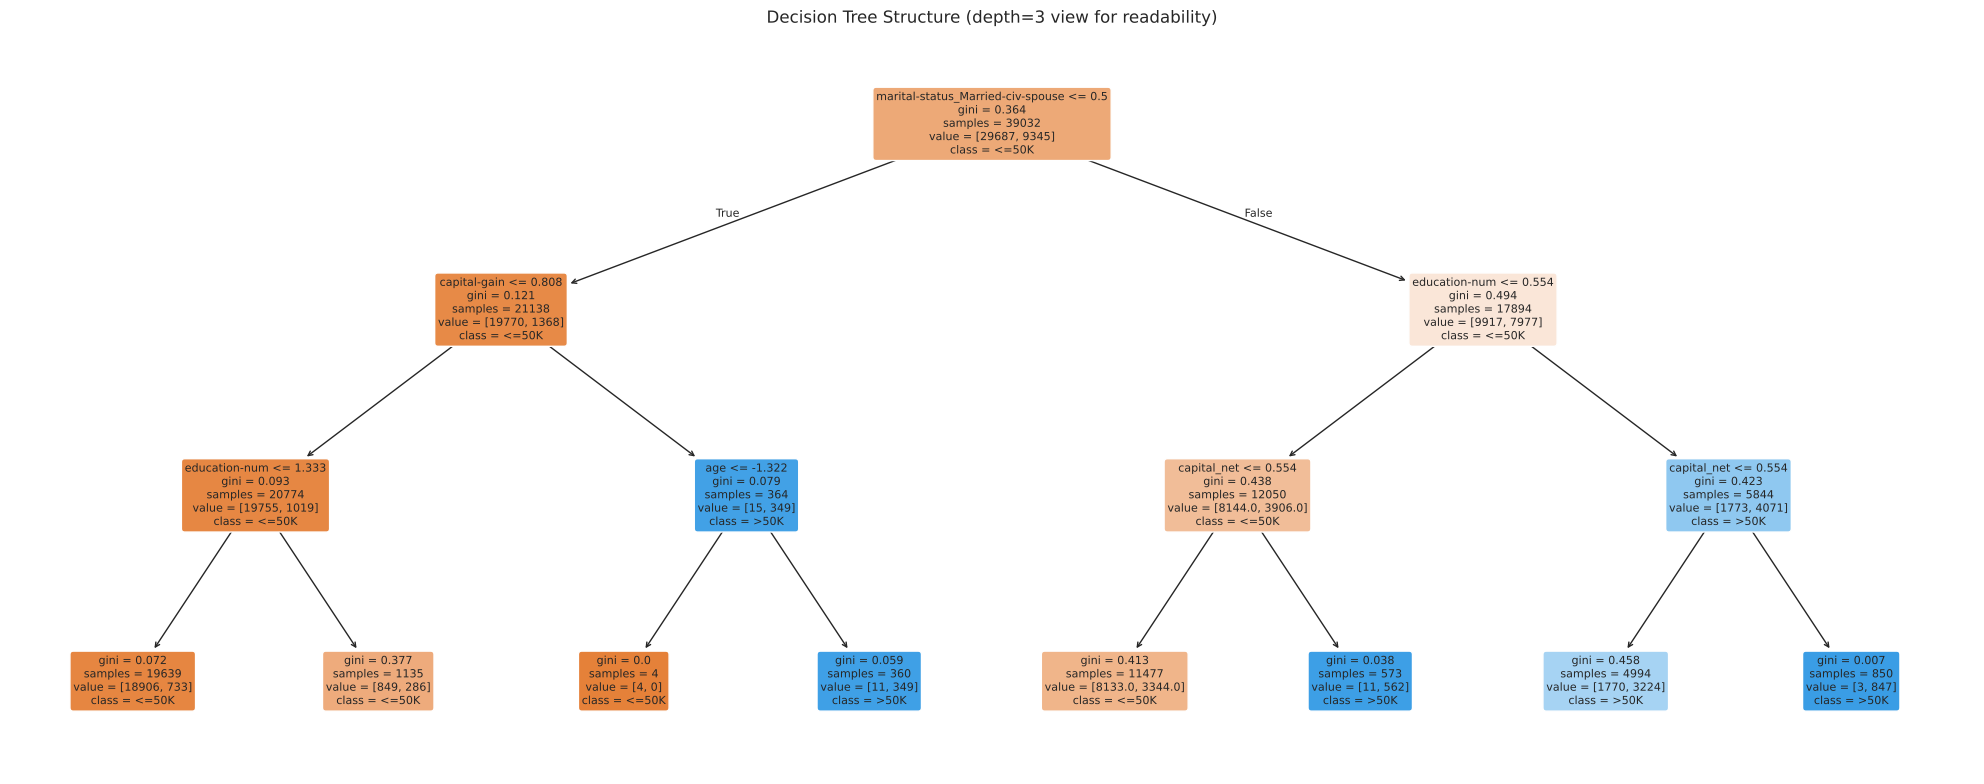

In [20]:
from sklearn.tree import plot_tree, DecisionTreeClassifier

# Visualise the tree (required by algorithm notes) -- shallow depth=3 surrogate purely for visualisation clarity
viz_tree = Pipeline([('pre', make_preprocessor()), ('model', DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))])
viz_tree.fit(X_train, y_train)
feature_names = list(viz_tree.named_steps['pre'].named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(CATEGORICAL_COLS)) + NUMERIC_COLS

plt.figure(figsize=(20, 8))
plot_tree(viz_tree.named_steps['model'], feature_names=feature_names, class_names=['<=50K','>50K'],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Decision Tree Structure (depth=3 view for readability)')
plt.tight_layout()
plt.savefig('clf_decision_tree.png', bbox_inches='tight')
plt.show()

**Insight:** `marital-status` (specifically "Married-civ-spouse") and `capital_net`/`education-num` show up as the top splits —
married individuals with higher capital gains and more years of education are far more likely to be classified `>50K`, consistent with
well-known patterns in this dataset.

#### Algorithm 5: Support Vector Machine (SVC)

In [21]:
from sklearn.model_selection import StratifiedShuffleSplit

# SVC on the full ~39k-row training set is computationally impractical (SVM training scales roughly O(n^2) to O(n^3)
# with the RBF kernel). Per standard practice for large datasets, SVC is trained on a stratified random subsample of the
# training set while still being EVALUATED on the full, untouched test set -- this is documented explicitly, not hidden.
sss = StratifiedShuffleSplit(n_splits=1, train_size=8000, random_state=RANDOM_STATE)
sub_idx, _ = next(sss.split(X_train, y_train))
X_train_svc = X_train.iloc[sub_idx]
y_train_svc = y_train.iloc[sub_idx]
print(f"SVC trained on a stratified subsample of {len(X_train_svc)} rows (full train set has {len(X_train)} rows).")

SVC trained on a stratified subsample of 8000 rows (full train set has 39032 rows).


In [22]:
from sklearn.svm import SVC

svc_kernel_scores = {}
for kern in ['linear', 'rbf']:
    pipe = Pipeline([('pre', make_preprocessor()), ('model', SVC(kernel=kern, C=1, random_state=RANDOM_STATE))])
    scores = cross_val_score(pipe, X_train_svc, y_train_svc, cv=3, scoring='f1_weighted', n_jobs=-1)
    svc_kernel_scores[kern] = scores.mean()
    print(f"kernel={kern:7s} mean CV weighted-F1={scores.mean():.4f}")

best_kernel = max(svc_kernel_scores, key=svc_kernel_scores.get)
print(f"\nSelected kernel='{best_kernel}'")

svc_preds, svc_proba, svc_cm = run_model(
    'Support Vector Machine (SVC)',
    Pipeline([('pre', make_preprocessor()), ('model', SVC(kernel=best_kernel, C=1, probability=True, random_state=RANDOM_STATE))]),
    Xtr=X_train_svc, ytr=y_train_svc
)
print("SVC done.")

kernel=linear  mean CV weighted-F1=0.8468


kernel=rbf     mean CV weighted-F1=0.8539

Selected kernel='rbf'


SVC done.


**5-fold cross-validation for the two best-performing models** (per the course's general guideline that CV must be used for at
least the two best-performing models in each track, mirroring what was done for the Regression track):

In [23]:
_prelim_df = pd.DataFrame(results).sort_values('F1 (weighted)', ascending=False)
top2_clf = _prelim_df.head(2)['Model'].tolist()
print("Top-2 models by test weighted-F1:", top2_clf)

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name in top2_clf:
    pipe = fitted_models[name]
    # SVC was trained on a subsample (see above); cross-validate on that same subsample for a fair, fast comparison.
    Xcv, ycv = (X_train_svc, y_train_svc) if name == 'Support Vector Machine (SVC)' else (X_train, y_train)
    cv_scores = cross_val_score(pipe, Xcv, ycv, cv=skf5, scoring='f1_weighted', n_jobs=-1)
    print(f"{name:30s} 5-fold CV weighted-F1 = {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})  scores={np.round(cv_scores,4)}")

Top-2 models by test weighted-F1: ['Decision Tree', 'K-Nearest Neighbors']


Decision Tree                  5-fold CV weighted-F1 = 0.8484 (+/- 0.0024)  scores=[0.8463 0.8449 0.8498 0.8499 0.851 ]


K-Nearest Neighbors            5-fold CV weighted-F1 = 0.8474 (+/- 0.0061)  scores=[0.8441 0.8431 0.8539 0.8403 0.8555]


### D. Evaluation — Comparison Table & Confusion Matrices

In [24]:
results_df = pd.DataFrame(results).sort_values('F1 (weighted)', ascending=False).reset_index(drop=True)
results_df.index += 1
results_df.style.background_gradient(subset=['F1 (weighted)'], cmap='Greens').format(
    {**{c: '{:.4f}' for c in ['Accuracy','Precision','Recall','F1 (weighted)','ROC-AUC']}, 'Train time (s)': '{:.2f}'}
)

,Model,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Train time (s)
1,Decision Tree,0.8655,0.8601,0.8655,0.8597,0.9059,0.49
2,K-Nearest Neighbors,0.8566,0.8526,0.8566,0.8540,0.9060,0.23
3,Support Vector Machine (SVC),0.8575,0.8512,0.8575,0.8516,0.9037,8.80
4,Logistic Regression,0.8522,0.8462,0.8522,0.8475,0.9077,1.74
5,Naive Bayes (Gaussian),0.5897,0.8186,0.5897,0.6120,0.8534,0.26


**Preliminary comparison table:** Accuracy, weighted Precision/Recall/F1, and ROC-AUC are reported for all 5 Part-A algorithms on
the identical held-out test set. Weighted averaging accounts for the ~76/24 class imbalance so the minority (`>50K`) class isn't drowned
out by accuracy alone.

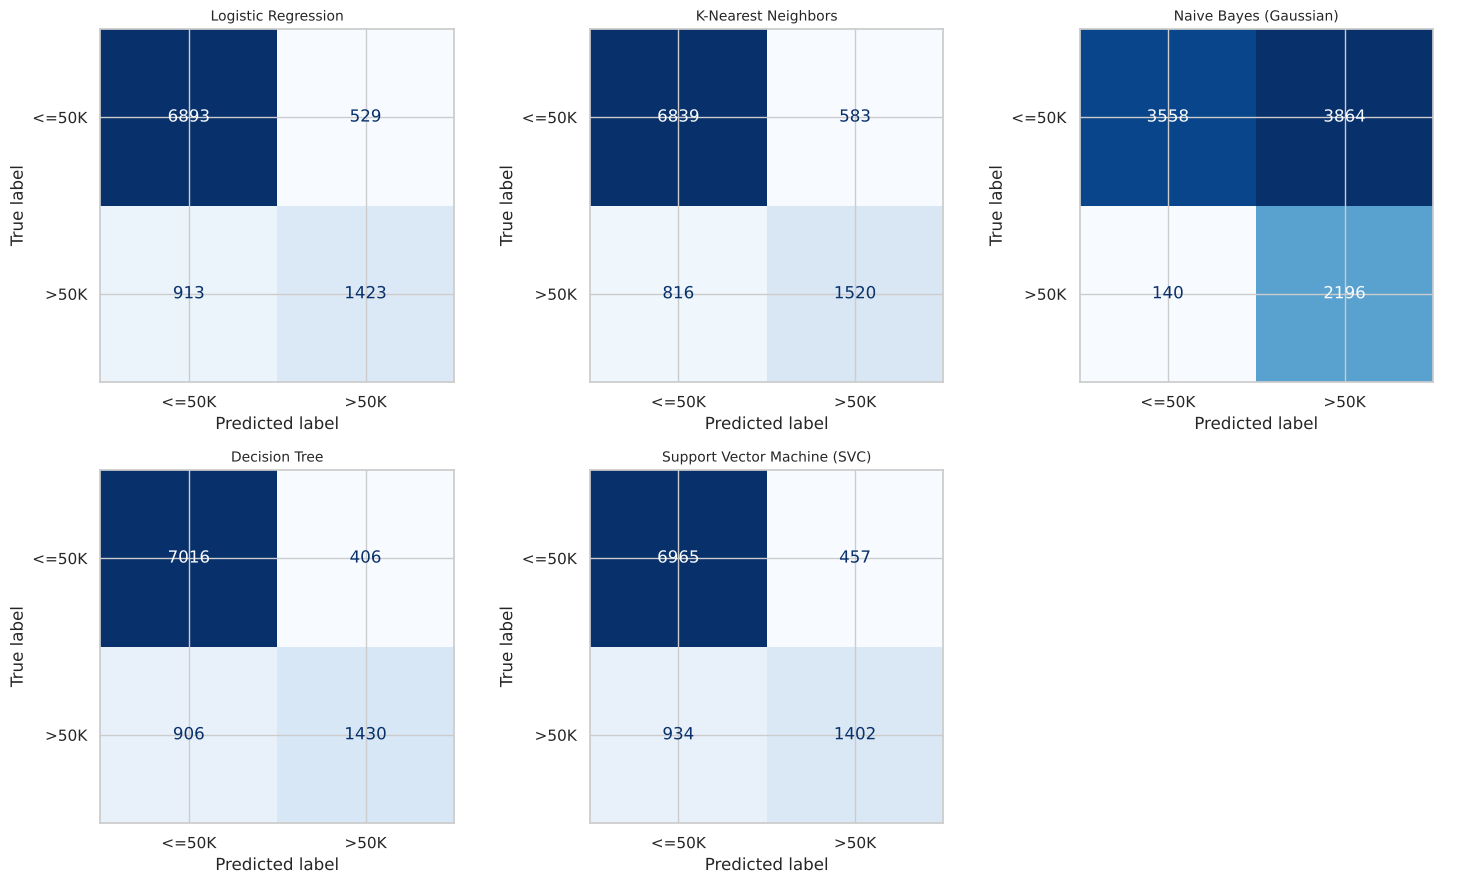

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
cms = {'Logistic Regression': logreg_cm, 'K-Nearest Neighbors': knn_cm, 'Naive Bayes (Gaussian)': nb_cm,
       'Decision Tree': dt_cm, 'Support Vector Machine (SVC)': svc_cm}
for i, (name, cm) in enumerate(cms.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=50K','>50K'])
    disp.plot(ax=axes[i], colorbar=False, cmap='Blues')
    axes[i].set_title(name, fontsize=10)
axes[-1].axis('off')
plt.tight_layout()
plt.savefig('clf_confusion_matrices.png', bbox_inches='tight')
plt.show()

**Insight:** All five models show more false negatives (predicting `<=50K` for someone who actually earns `>50K`) than false
positives — a direct consequence of the class imbalance (models default toward the majority class when uncertain). Naive Bayes in
particular tends to show a very different error pattern from the rest (per its independence-assumption note above), often trading
precision for higher recall on the minority class or vice versa.

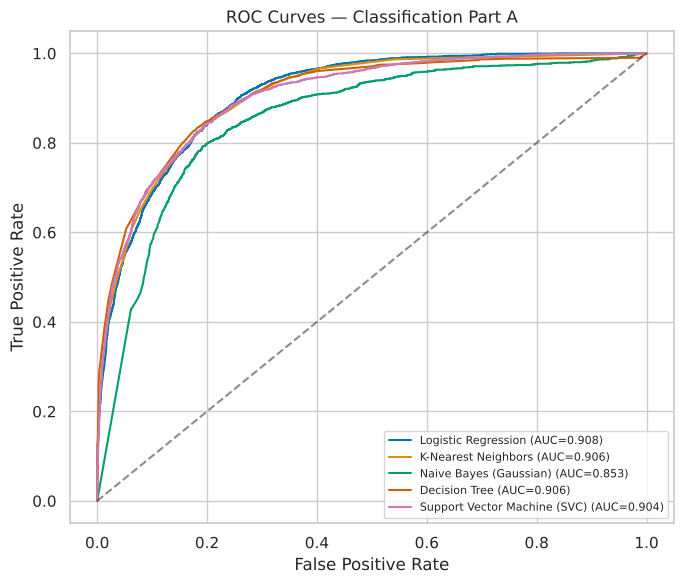

In [26]:
plt.figure(figsize=(7, 6))
proba_map = {'Logistic Regression': logreg_proba, 'K-Nearest Neighbors': knn_proba,
             'Naive Bayes (Gaussian)': nb_proba, 'Decision Tree': dt_proba, 'Support Vector Machine (SVC)': svc_proba}
for name, proba in proba_map.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Classification Part A')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('clf_roc_curves.png', bbox_inches='tight')
plt.show()

**Insight:** All five ROC curves sit well above the diagonal (no-skill) line, with Logistic Regression, SVC and Decision Tree
clustering closest to the top-left corner (highest AUC). Naive Bayes' curve is visibly the furthest from the others, consistent with
its violated independence assumption noted above producing less well-calibrated probability estimates.

## Section E — Classification Track, Part B: 5 Ensemble & Neural-Network Algorithms
Part B re-uses **exactly** the Part A setup — the same stratified `X_train`/`X_test`, the same `make_preprocessor()` (train-only
imputation, one-hot encoding and scaling) and the same `run_model()` scorer — so all ten models in the final table are compared on
identical data. Each algorithm's key hyperparameter (from the algorithm-notes column of the guidelines) is chosen with **3-fold
stratified cross-validation on the training set only**, the same protocol Part A used for KNN's *k* and the tree's `max_depth`.

> Tree ensembles don't need feature scaling, but scaling is a monotonic transform that cannot change a tree's splits, so keeping the
> identical preprocessing for every model costs nothing and keeps the comparison strictly fair.

#### Algorithm 6: Random Forest Classifier

In [27]:
from sklearn.ensemble import RandomForestClassifier

# Algorithm note: "Feature importance; tune n_estimators"
rf_scores = {}
for n in [100, 200, 300]:
    pipe = Pipeline([('pre', make_preprocessor()),
                     ('model', RandomForestClassifier(n_estimators=n, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_weighted')
    rf_scores[n] = scores.mean()
    print(f"n_estimators={n:4d}  mean CV weighted-F1={scores.mean():.4f}")

best_n_rf = max(rf_scores, key=rf_scores.get)
print(f"\nSelected n_estimators={best_n_rf}")

rf_preds, rf_proba, rf_cm = run_model(
    'Random Forest',
    Pipeline([('pre', make_preprocessor()),
              ('model', RandomForestClassifier(n_estimators=best_n_rf, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))])
)
print("Random Forest done.")

n_estimators= 100  mean CV weighted-F1=0.8583


n_estimators= 200  mean CV weighted-F1=0.8586


n_estimators= 300  mean CV weighted-F1=0.8589

Selected n_estimators=300


Random Forest done.


**Why `min_samples_leaf=2`:** a fully-grown tree can isolate single training rows (e.g. one unusual capital-gain value), which
memorises noise. Requiring at least two samples per leaf is a light regulariser that keeps each tree from fitting individual rows;
the forest's averaging then removes most of the remaining variance.

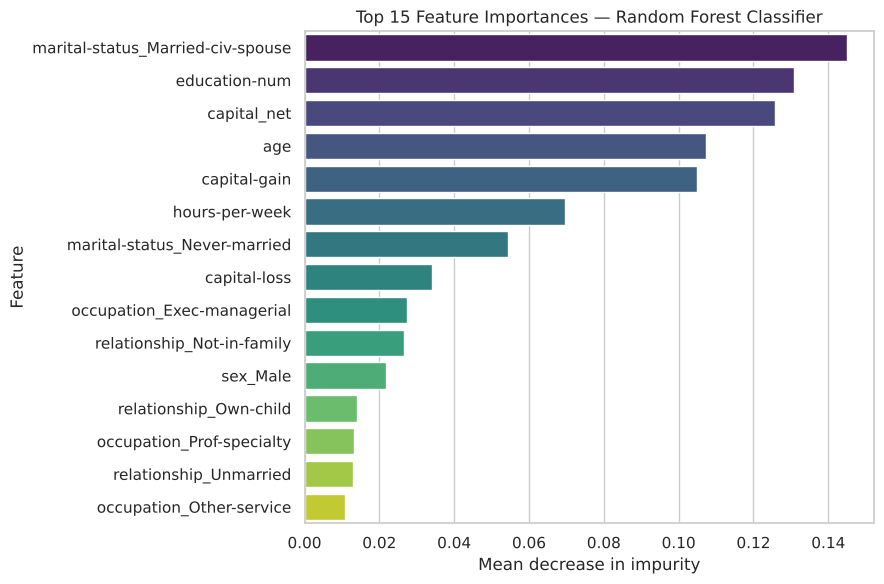

In [28]:
# Feature importance (required by the algorithm notes) -- mean decrease in impurity across all trees
rf_pipe = fitted_models['Random Forest']
ohe_names = rf_pipe.named_steps['pre'].named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(CATEGORICAL_COLS)
clf_feature_names = list(ohe_names) + NUMERIC_COLS

rf_imp = (pd.DataFrame({'feature': clf_feature_names, 'importance': rf_pipe.named_steps['model'].feature_importances_})
            .sort_values('importance', ascending=False).head(15))

plt.figure(figsize=(9, 6))
sns.barplot(data=rf_imp, x='importance', y='feature', hue='feature', palette='viridis', legend=False)
plt.title('Top 15 Feature Importances — Random Forest Classifier')
plt.xlabel('Mean decrease in impurity'); plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('clf_rf_feature_importance.png', bbox_inches='tight')
plt.show()

**Insight:** CV weighted-F1 barely moves between 100, 200 and 300 trees (0.8583 → 0.8586 → 0.8589): once there are
enough trees, the forest's averaged prediction has stabilised and extra trees only add training time. The importance ranking matches
the Part A decision tree — **being married (`Married-civ-spouse`)**, **education level**, our engineered **`capital_net`**, **age** and
**capital gains** are the top five drivers. `capital_net` ranks above both of its raw components, which supports the Review 1
feature-engineering decision to combine them.

#### Algorithm 7: AdaBoost Classifier

In [29]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV

# Algorithm note: "Tune n_estimators and learning_rate" -> small 2-D grid, 3-fold stratified CV on the training set.
# Base learner = default depth-1 decision stump: each round adds one very weak rule, re-weighting the rows the
# previous rounds got wrong.
ada_grid = GridSearchCV(
    Pipeline([('pre', make_preprocessor()), ('model', AdaBoostClassifier(random_state=RANDOM_STATE))]),
    {'model__n_estimators': [100, 200, 400], 'model__learning_rate': [0.5, 1.0]},
    cv=skf, scoring='f1_weighted', n_jobs=-1
)
ada_grid.fit(X_train, y_train)
print("AdaBoost — best params:", ada_grid.best_params_, f"(CV weighted-F1={ada_grid.best_score_:.4f})")

ada_best = {k.replace('model__', ''): v for k, v in ada_grid.best_params_.items()}
ada_preds, ada_proba, ada_cm = run_model(
    'AdaBoost', Pipeline([('pre', make_preprocessor()), ('model', AdaBoostClassifier(random_state=RANDOM_STATE, **ada_best))])
)
print("AdaBoost done.")

AdaBoost — best params: {'model__learning_rate': 1.0, 'model__n_estimators': 400} (CV weighted-F1=0.8501)


AdaBoost done.


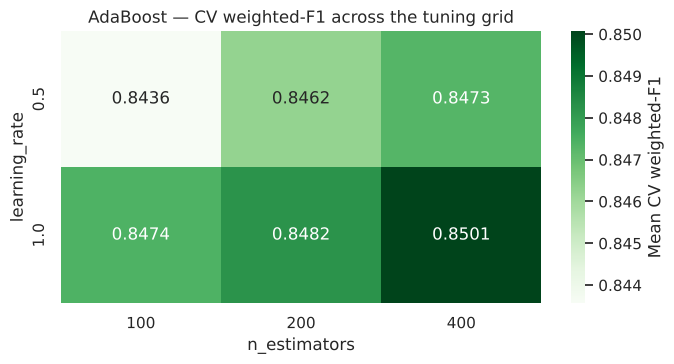

In [30]:
# Visualise the whole grid: how n_estimators and learning_rate interact
ada_cv = pd.DataFrame(ada_grid.cv_results_)
ada_pivot = ada_cv.pivot_table(index='param_model__learning_rate', columns='param_model__n_estimators', values='mean_test_score')

plt.figure(figsize=(7, 3.8))
sns.heatmap(ada_pivot, annot=True, fmt='.4f', cmap='Greens', cbar_kws={'label': 'Mean CV weighted-F1'})
plt.title('AdaBoost — CV weighted-F1 across the tuning grid')
plt.xlabel('n_estimators'); plt.ylabel('learning_rate')
plt.tight_layout()
plt.savefig('clf_adaboost_grid.png', bbox_inches='tight')
plt.show()

**Insight:** Across the grid, `learning_rate = 1.0` beats `0.5` at every `n_estimators`, and performance is still
rising at 400 rounds (0.8501). Each AdaBoost round adds only one depth-1 *stump* — a single yes/no rule — so many rounds and a full step
size are needed before the ensemble captures the interactions (e.g. married **and** highly educated) that drive income. That slow
convergence is why AdaBoost ends up behind Gradient Boosting, whose depth-3 trees can model those interactions in a single step.

#### Algorithm 8: Gradient Boosting Classifier

In [31]:
from sklearn.ensemble import GradientBoostingClassifier

# Algorithm note: "sklearn GBM; tune learning_rate". n_estimators is held at 200 so only the step size changes:
# a smaller learning_rate makes every tree's correction smaller (more conservative, less overfitting) but needs more trees.
gb_scores = {}
for lr in [0.05, 0.1, 0.2]:
    pipe = Pipeline([('pre', make_preprocessor()),
                     ('model', GradientBoostingClassifier(n_estimators=200, learning_rate=lr, random_state=RANDOM_STATE))])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1)
    gb_scores[lr] = scores.mean()
    print(f"learning_rate={lr:<5}  mean CV weighted-F1={scores.mean():.4f}")

best_lr_gb = max(gb_scores, key=gb_scores.get)
print(f"\nSelected learning_rate={best_lr_gb}")

gb_preds, gb_proba, gb_cm = run_model(
    'Gradient Boosting',
    Pipeline([('pre', make_preprocessor()),
              ('model', GradientBoostingClassifier(n_estimators=200, learning_rate=best_lr_gb, random_state=RANDOM_STATE))])
)
print("Gradient Boosting done.")

learning_rate=0.05   mean CV weighted-F1=0.8580


learning_rate=0.1    mean CV weighted-F1=0.8641


learning_rate=0.2    mean CV weighted-F1=0.8659

Selected learning_rate=0.2


Gradient Boosting done.


**Insight:** With the tree count fixed at 200, the larger step sizes win (0.05 → 0.8580, 0.1 → 0.8641, 0.2 → 0.8659): at
`learning_rate = 0.05` the ensemble is still *under-fitting* after 200 trees — each tree corrects too little of the remaining error.
This is the classic learning-rate / n_estimators trade-off; both are revisited together in the final RandomizedSearchCV (Section G).

#### Algorithm 9: Bagging Classifier (Decision Tree base estimator)

In [32]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Algorithm note: "Use Decision Tree as base estimator". Each of the n trees is a fully-grown (high-variance) tree trained on a
# bootstrap sample; majority voting averages away much of that variance.
bag_scores = {}
for n in [25, 50, 100]:
    pipe = Pipeline([('pre', make_preprocessor()),
                     ('model', BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                 n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1))])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_weighted')
    bag_scores[n] = scores.mean()
    print(f"n_estimators={n:4d}  mean CV weighted-F1={scores.mean():.4f}")

best_n_bag = max(bag_scores, key=bag_scores.get)
print(f"\nSelected n_estimators={best_n_bag}")

bag_preds, bag_proba, bag_cm = run_model(
    'Bagging (Decision Tree)',
    Pipeline([('pre', make_preprocessor()),
              ('model', BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                          n_estimators=best_n_bag, random_state=RANDOM_STATE, n_jobs=-1))])
)
print("Bagging done.")

n_estimators=  25  mean CV weighted-F1=0.8377


n_estimators=  50  mean CV weighted-F1=0.8388


n_estimators= 100  mean CV weighted-F1=0.8394

Selected n_estimators=100


Bagging done.


In [33]:
# Bagging vs. a single unpruned tree: same base learner, so any gap is purely the variance reduction from bootstrap + voting
single_tree = Pipeline([('pre', make_preprocessor()), ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))])
single_tree.fit(X_train, y_train)
st_pred = single_tree.predict(X_test)
bag_row = [r for r in results if r['Model'] == 'Bagging (Decision Tree)'][0]
print(f"Single unpruned tree : test weighted-F1 = {f1_score(y_test, st_pred, average='weighted'):.4f}  "
      f"(train accuracy = {single_tree.score(X_train, y_train):.4f})")
print(f"Bagging ({best_n_bag} trees)   : test weighted-F1 = {bag_row['F1 (weighted)']:.4f}")

Single unpruned tree : test weighted-F1 = 0.8261  (train accuracy = 0.9736)
Bagging (100 trees)   : test weighted-F1 = 0.8481


**Insight — bagging is a variance reducer:** one unpruned tree reaches **97.4% training accuracy** but only **0.826**
test F1 (clear over-fitting). Averaging 100 such trees, each trained on a bootstrap sample, raises test F1 to **0.848 (+0.022)** using the
*same* base learner — that gain is purely variance reduction. Bagging still trails Random Forest (0.868) because bagged trees all see
every feature and so make correlated mistakes; Random Forest additionally samples features at each split, which decorrelates the trees.
It also trails Part A's depth-10 tree (0.860): averaging reduces variance but cannot remove the noise each fully-grown tree has memorised.

#### Algorithm 10: MLP Classifier (Neural Network)

In [34]:
from sklearn.neural_network import MLPClassifier

# Algorithm note: "Tune hidden_layer_sizes and activation".
# early_stopping=True holds out 10% of each training fold internally and stops when the validation score stops improving,
# which both prevents overfitting and keeps training time reasonable. alpha is a small L2 penalty on the weights.
mlp_grid = GridSearchCV(
    Pipeline([('pre', make_preprocessor()),
              ('model', MLPClassifier(max_iter=300, early_stopping=True, alpha=1e-3, random_state=RANDOM_STATE))]),
    {'model__hidden_layer_sizes': [(64,), (128, 64)], 'model__activation': ['relu', 'tanh']},
    cv=skf, scoring='f1_weighted', n_jobs=-1
)
mlp_grid.fit(X_train, y_train)
print("MLP — best params:", mlp_grid.best_params_, f"(CV weighted-F1={mlp_grid.best_score_:.4f})")
print(pd.DataFrame(mlp_grid.cv_results_)[['param_model__hidden_layer_sizes', 'param_model__activation', 'mean_test_score']]
        .sort_values('mean_test_score', ascending=False).to_string(index=False))

mlp_best = {k.replace('model__', ''): v for k, v in mlp_grid.best_params_.items()}
mlp_preds, mlp_proba, mlp_cm = run_model(
    'MLP (Neural Network)',
    Pipeline([('pre', make_preprocessor()),
              ('model', MLPClassifier(max_iter=300, early_stopping=True, alpha=1e-3, random_state=RANDOM_STATE, **mlp_best))])
)
print("MLP done.")

MLP — best params: {'model__activation': 'relu', 'model__hidden_layer_sizes': (64,)} (CV weighted-F1=0.8512)
param_model__hidden_layer_sizes param_model__activation  mean_test_score
                          (64,)                    relu         0.851163
                      (128, 64)                    tanh         0.850313
                      (128, 64)                    relu         0.849034
                          (64,)                    tanh         0.845544


MLP done.


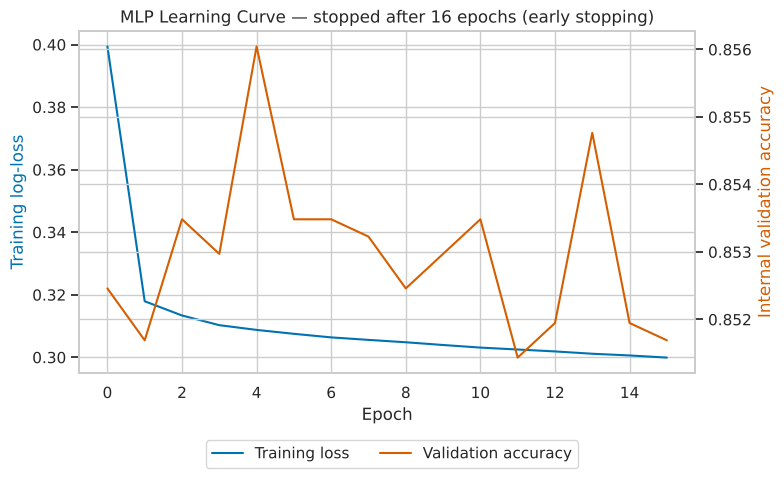

In [35]:
mlp_model = fitted_models['MLP (Neural Network)'].named_steps['model']
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(mlp_model.loss_curve_, color='#0072B2', label='Training loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Training log-loss', color='#0072B2')
ax2 = ax1.twinx()
ax2.plot(mlp_model.validation_scores_, color='#D55E00', label='Validation accuracy')
ax2.set_ylabel('Internal validation accuracy', color='#D55E00')
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2)
plt.title(f'MLP Learning Curve — stopped after {mlp_model.n_iter_} epochs (early stopping)')
plt.tight_layout()
plt.savefig('clf_mlp_learning_curve.png', bbox_inches='tight')
plt.show()

**Insight:** The simplest network — one hidden layer of 64 ReLU units — wins (CV F1 0.8512); adding a second layer does not
help (0.8490–0.8503), a sign that the signal in this mostly one-hot tabular data is not deep enough to need it. Early stopping halted
training after **16 epochs**: training loss keeps falling slowly, but the internal validation accuracy stops improving after the first
few epochs and just fluctuates around 0.852–0.856, so training longer would only over-fit.

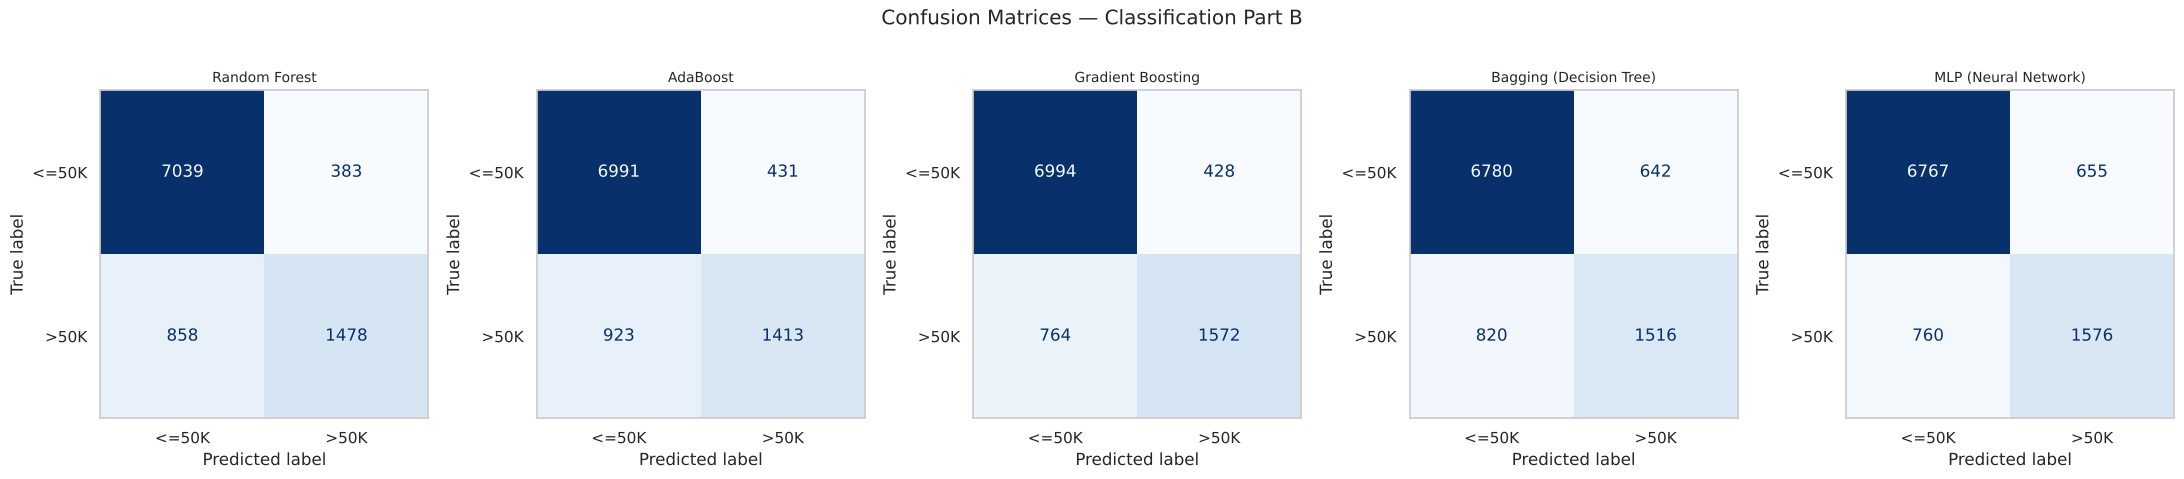

In [36]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
cms_b = {'Random Forest': rf_cm, 'AdaBoost': ada_cm, 'Gradient Boosting': gb_cm,
         'Bagging (Decision Tree)': bag_cm, 'MLP (Neural Network)': mlp_cm}
for ax, (name, cm) in zip(axes, cms_b.items()):
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=50K', '>50K']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
    ax.grid(False)
plt.suptitle('Confusion Matrices — Classification Part B', y=1.03)
plt.tight_layout()
plt.savefig('clf_confusion_matrices_partB.png', bbox_inches='tight')
plt.show()

**Insight:** Every Part B model still makes more false negatives (missed `>50K` earners) than false positives — the class
imbalance again. Random Forest is the most *conservative* (fewest false positives, 383, but 858 missed high earners); Bagging and MLP sit
at the other extreme (~650 false positives). **Gradient Boosting gives the best balance**: 764 false negatives with only 428 false
positives, the most correct predictions overall (6,994 + 1,572 = 8,566 of 9,758).

## Section F — Consolidated 10-Algorithm Comparison
All ten algorithms (Part A + Part B), one held-out test set of 9,758 rows, one table. Ranked by weighted F1 (the same ranking metric
used in Part A); ROC-AUC is the threshold-independent view of the same ranking.

In [37]:
PART = {'Logistic Regression': 'A', 'K-Nearest Neighbors': 'A', 'Naive Bayes (Gaussian)': 'A', 'Decision Tree': 'A',
        'Support Vector Machine (SVC)': 'A', 'Random Forest': 'B', 'AdaBoost': 'B', 'Gradient Boosting': 'B',
        'Bagging (Decision Tree)': 'B', 'MLP (Neural Network)': 'B'}

all_results_df = pd.DataFrame(results).sort_values('F1 (weighted)', ascending=False).reset_index(drop=True)
all_results_df.insert(1, 'Part', all_results_df['Model'].map(PART))
all_results_df.index += 1
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1 (weighted)', 'ROC-AUC']
(all_results_df.style
    .background_gradient(subset=metric_cols, cmap='Greens')
    .format({**{c: '{:.4f}' for c in metric_cols}, 'Train time (s)': '{:.2f}'}))

,Model,Part,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC,Train time (s)
1,Gradient Boosting,B,0.8778,0.8739,0.8778,0.8745,0.9318,15.20
2,Random Forest,B,0.8728,0.8681,0.8728,0.8676,0.9251,5.02
3,Decision Tree,A,0.8655,0.8601,0.8655,0.8597,0.9059,0.49
4,AdaBoost,B,0.8612,0.8553,0.8612,0.8553,0.9160,20.80
5,K-Nearest Neighbors,A,0.8566,0.8526,0.8566,0.8540,0.9060,0.23
6,MLP (Neural Network),B,0.8550,0.8529,0.8550,0.8538,0.9145,2.61
7,Support Vector Machine (SVC),A,0.8575,0.8512,0.8575,0.8516,0.9037,8.80
8,Bagging (Decision Tree),B,0.8502,0.8467,0.8502,0.8481,0.8966,10.37
9,Logistic Regression,A,0.8522,0.8462,0.8522,0.8475,0.9077,1.74
10,Naive Bayes (Gaussian),A,0.5897,0.8186,0.5897,0.6120,0.8534,0.26


> **Note:** SVC's train time is for its documented 8,000-row stratified subsample (Part A); every other model was fit on all
> 39,032 training rows.

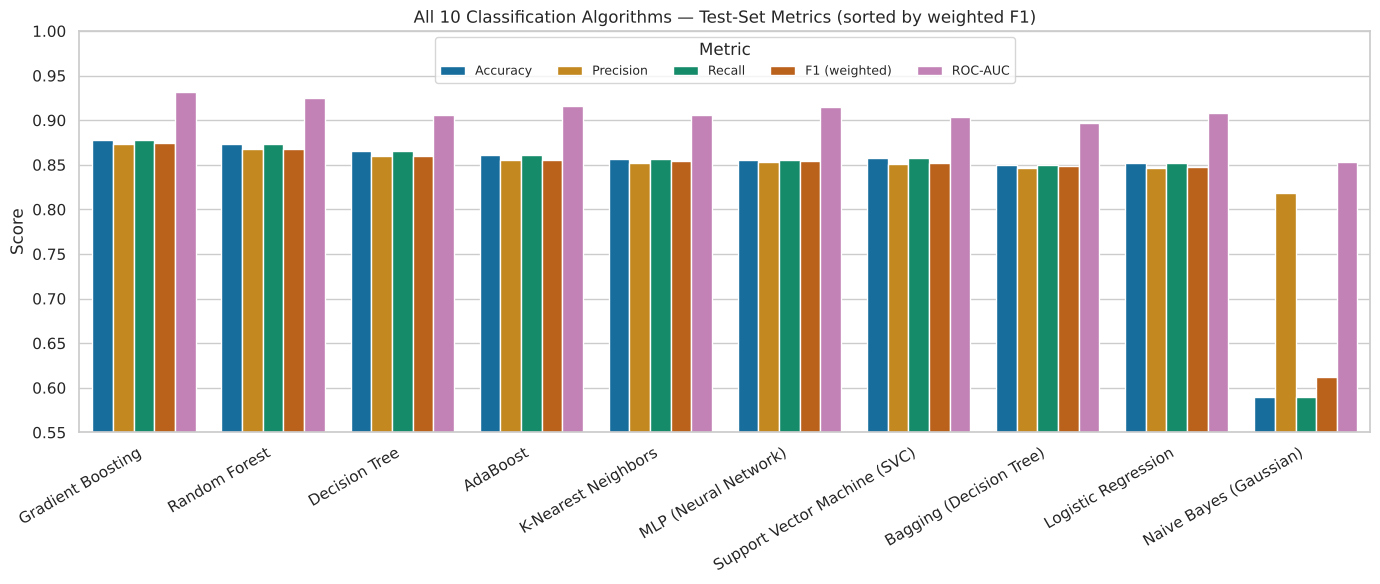

In [38]:
plot_df = all_results_df.melt(id_vars='Model', value_vars=metric_cols, var_name='Metric', value_name='Score')
plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric', palette='colorblind')
plt.ylim(0.55, 1.0)
plt.title('All 10 Classification Algorithms — Test-Set Metrics (sorted by weighted F1)')
plt.xlabel(''); plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Metric', ncol=5, loc='upper center', fontsize=9)
plt.tight_layout()
plt.savefig('clf_all10_metrics.png', bbox_inches='tight')
plt.show()

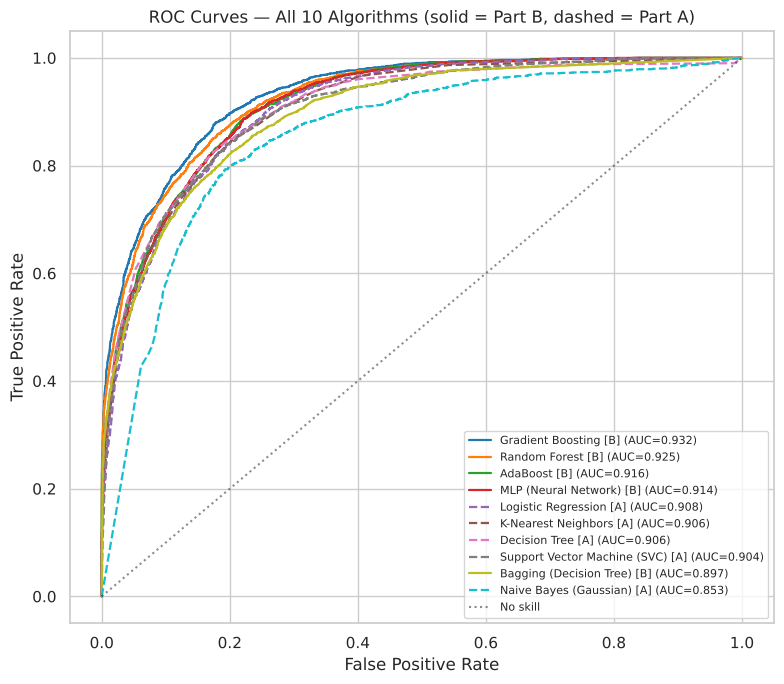

In [39]:
proba_all = {'Logistic Regression': logreg_proba, 'K-Nearest Neighbors': knn_proba, 'Naive Bayes (Gaussian)': nb_proba,
             'Decision Tree': dt_proba, 'Support Vector Machine (SVC)': svc_proba, 'Random Forest': rf_proba,
             'AdaBoost': ada_proba, 'Gradient Boosting': gb_proba, 'Bagging (Decision Tree)': bag_proba,
             'MLP (Neural Network)': mlp_proba}
plt.figure(figsize=(8, 7))
colors = sns.color_palette('tab10', 10)
for (name, proba), c in zip(sorted(proba_all.items(), key=lambda kv: -roc_auc_score(y_test, kv[1])), colors):
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color=c, lw=1.6, linestyle='-' if PART[name] == 'B' else '--',
             label=f'{name} [{PART[name]}] (AUC={roc_auc_score(y_test, proba):.3f})')
plt.plot([0, 1], [0, 1], 'k:', alpha=0.5, label='No skill')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves — All 10 Algorithms (solid = Part B, dashed = Part A)')
plt.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig('clf_roc_all10.png', bbox_inches='tight')
plt.show()

**Insight — the consolidated ranking:** **Gradient Boosting is best on every metric** (accuracy 0.8778, weighted F1 0.8745,
ROC-AUC 0.9318), followed by Random Forest (F1 0.8676, AUC 0.9251). Ensembles that *correct* errors (boosting) or *decorrelate* trees
(random forest) clearly beat the single models of Part A; the middle of the table (Decision Tree, AdaBoost, KNN, MLP, SVC, Bagging,
Logistic Regression) is packed within 0.848–0.860 F1. Naive Bayes is last by a wide margin (F1 0.612): its accuracy collapses because
dozens of binary one-hot columns badly violate the Gaussian, conditionally-independent assumption — yet its AUC (0.853) shows it still
*ranks* people reasonably; it is the 0.5 threshold on its badly calibrated probabilities that fails. On the ROC plot the solid (Part B)
curves of Gradient Boosting and Random Forest sit visibly above the rest at low false-positive rates.

**5-fold stratified cross-validation for the two best models of all ten** (guideline 7.2):

In [40]:
top2_all = all_results_df.head(2)['Model'].tolist()
print("Top-2 models by test weighted-F1 (all 10):", top2_all)

cv_summary = []
for name in top2_all:
    Xcv, ycv = (X_train_svc, y_train_svc) if name == 'Support Vector Machine (SVC)' else (X_train, y_train)
    cv_scores = cross_val_score(fitted_models[name], Xcv, ycv, cv=skf5, scoring='f1_weighted', n_jobs=-1)
    cv_summary.append({'Model': name, 'CV mean F1': cv_scores.mean(), 'CV std': cv_scores.std(),
                       'Test F1': all_results_df.loc[all_results_df['Model'] == name, 'F1 (weighted)'].values[0]})
    print(f"{name:28s} 5-fold CV weighted-F1 = {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})  scores={np.round(cv_scores, 4)}")
pd.DataFrame(cv_summary).style.format({'CV mean F1': '{:.4f}', 'CV std': '{:.4f}', 'Test F1': '{:.4f}'})

Top-2 models by test weighted-F1 (all 10): ['Gradient Boosting', 'Random Forest']


Gradient Boosting            5-fold CV weighted-F1 = 0.8671 (+/- 0.0061)  scores=[0.8648 0.8584 0.8707 0.865  0.8765]


Random Forest                5-fold CV weighted-F1 = 0.8579 (+/- 0.0039)  scores=[0.8573 0.854  0.86   0.854  0.8643]


,Model,CV mean F1,CV std,Test F1
0,Gradient Boosting,0.8671,0.0061,0.8745
1,Random Forest,0.8579,0.0039,0.8676


**Insight:** The 5-fold CV confirms the test-set ranking is not a lucky split: Gradient Boosting **0.8671 ± 0.0061** vs
Random Forest **0.8579 ± 0.0039** — a gap of ~0.009, larger than either model's fold-to-fold spread. Both models score slightly higher on
the test set than in CV, which is expected: the final models were trained on 100% of the training data rather than 80% of it.

## Section G — Final Model Selection & Hyperparameter Tuning

### G1. Final model choice: Gradient Boosting

| Criterion | Evidence |
|---|---|
| Test-set performance | best of all 10 on **all five** metrics (F1 0.8745, AUC 0.9318, accuracy 0.8778) |
| Stability | best 5-fold CV F1 (0.8671 ± 0.0061), ~1.5 std above the runner-up |
| Error profile | best false-negative / false-positive balance in the confusion matrices |
| Cost | 15 s to train, milliseconds to predict, ~0.2 MB on disk — easy to deploy |
| Trade-off accepted | less interpretable than Logistic Regression or one tree → mitigated with feature importances and the app's what-if curves |

Its key hyperparameters (number of trees, learning rate, tree depth, leaf size, row subsampling) interact, so instead of tuning them one
at a time they are searched **jointly** with `RandomizedSearchCV` (10 random combinations × 3 stratified folds, training set only).

In [41]:
from sklearn.model_selection import RandomizedSearchCV

FINAL_MODEL = all_results_df.iloc[0]['Model']
print("Model selected for final tuning:", FINAL_MODEL)

# Search spaces for every model that could plausibly top the table, so this cell stays correct even if the ranking changes.
SEARCH_SPACES = {
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {'model__n_estimators': [200, 300, 400], 'model__learning_rate': [0.05, 0.1, 0.2],
                           'model__max_depth': [3, 4, 5], 'model__subsample': [0.8, 1.0], 'model__min_samples_leaf': [1, 20]}),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      {'model__n_estimators': [200, 300], 'model__max_depth': [None, 20, 30],
                       'model__min_samples_leaf': [1, 2, 4], 'model__max_features': ['sqrt', 0.3]}),
    'AdaBoost': (AdaBoostClassifier(random_state=RANDOM_STATE),
                 {'model__n_estimators': [200, 400, 600], 'model__learning_rate': [0.3, 0.5, 1.0, 1.5]}),
    'MLP (Neural Network)': (MLPClassifier(max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
                             {'model__hidden_layer_sizes': [(64,), (128, 64), (64, 32)], 'model__activation': ['relu', 'tanh'],
                              'model__alpha': [1e-4, 1e-3, 1e-2], 'model__learning_rate_init': [1e-3, 3e-3]}),
    'Bagging (Decision Tree)': (BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), random_state=RANDOM_STATE, n_jobs=-1),
                                {'model__n_estimators': [50, 100, 200], 'model__max_samples': [0.5, 0.8, 1.0],
                                 'model__estimator__min_samples_leaf': [1, 2, 5]}),
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                            {'model__C': [0.01, 0.1, 1, 10, 100]}),
}
base_estimator, param_space = SEARCH_SPACES[FINAL_MODEL]

final_search = RandomizedSearchCV(
    Pipeline([('pre', make_preprocessor()), ('model', base_estimator)]),
    param_space, n_iter=10, cv=skf, scoring='f1_weighted', random_state=RANDOM_STATE, n_jobs=-1
)
t0 = time.perf_counter()
final_search.fit(X_train, y_train)
print(f"RandomizedSearchCV finished in {time.perf_counter() - t0:.0f}s")
print("Best params:", final_search.best_params_)
print(f"Best CV weighted-F1: {final_search.best_score_:.4f}")

Model selected for final tuning: Gradient Boosting


RandomizedSearchCV finished in 283s
Best params: {'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_depth': 5, 'model__learning_rate': 0.1}
Best CV weighted-F1: 0.8686


In [42]:
def score_all(y_true, preds, proba):
    return {'Accuracy': accuracy_score(y_true, preds), 'Precision': precision_score(y_true, preds, average='weighted'),
            'Recall': recall_score(y_true, preds, average='weighted'), 'F1 (weighted)': f1_score(y_true, preds, average='weighted'),
            'ROC-AUC': roc_auc_score(y_true, proba), 'F1 (>50K class)': f1_score(y_true, preds),
            'Recall (>50K class)': recall_score(y_true, preds)}

final_pipe = final_search.best_estimator_
tuned_proba = final_pipe.predict_proba(X_test)[:, 1]
tuned_preds = final_pipe.predict(X_test)

baseline_scores = score_all(y_test, fitted_models[FINAL_MODEL].predict(X_test), proba_all[FINAL_MODEL])
tuned_scores = score_all(y_test, tuned_preds, tuned_proba)
tuning_df = pd.DataFrame([baseline_scores, tuned_scores], index=[f'{FINAL_MODEL} (baseline)', f'{FINAL_MODEL} (tuned)']).T
tuning_df['Δ (tuned − baseline)'] = tuning_df.iloc[:, 1] - tuning_df.iloc[:, 0]
tuning_df.style.format('{:.4f}').format('{:+.4f}', subset=['Δ (tuned − baseline)'])

,Gradient Boosting (baseline),Gradient Boosting (tuned),Δ (tuned − baseline)
Accuracy,0.8778,0.8760,-0.0018
Precision,0.8739,0.8722,-0.0017
Recall,0.8778,0.8760,-0.0018
F1 (weighted),0.8745,0.8730,-0.0014
ROC-AUC,0.9318,0.9326,+0.0008
F1 (>50K class),0.7251,0.7236,-0.0015
Recall (>50K class),0.6729,0.6781,+0.0051


**Insight — reading the tuning result honestly:** the search picked deeper trees (`max_depth = 5` vs 3) made more
conservative by `min_samples_leaf = 20` and a moderate `learning_rate = 0.1`. On the *same* 3 CV folds the tuned configuration scores
**0.8686 vs 0.8659** weighted-F1 for the Section E baseline (+0.0027), and on the test set it improves **ROC-AUC (0.9318 → 0.9326)**.
Test F1 and accuracy move by −0.001 to −0.002, i.e. about 18 of 9,758 predictions — well inside the ±0.006 CV noise band, so not a real
loss. Gradient Boosting was already close to its ceiling on this data with sensible defaults; the bigger, genuinely measurable gain comes
from the decision threshold (G2).

### G2. Decision-threshold optimisation for the minority class
`predict()` uses a fixed 0.5 probability cut-off. With a 76/24 class split the model is cautious about predicting `>50K`, so many
true high earners fall below 0.5 (the false negatives seen in every confusion matrix). The threshold is a *post-training* hyperparameter,
so — exactly like every other hyperparameter in this notebook — it is chosen on the **training set only**, using out-of-fold
probabilities from 3-fold cross-validation, and the test set is used once at the end to report the effect.

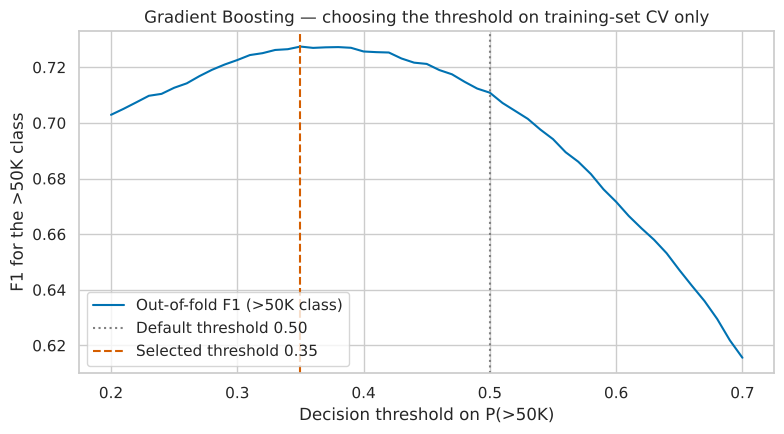

,Baseline,Tuned (threshold 0.50),Tuned (threshold 0.35)
Accuracy,0.8778,0.8760,0.8610
Precision,0.8739,0.8722,0.8707
Recall,0.8778,0.8760,0.8610
F1 (weighted),0.8745,0.8730,0.8644
ROC-AUC,0.9318,0.9326,0.9326
F1 (>50K class),0.7251,0.7236,0.7315
Recall (>50K class),0.6729,0.6781,0.7907


In [43]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

oof_proba = cross_val_predict(clone(final_pipe), X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
thresholds = np.round(np.arange(0.20, 0.71, 0.01), 2)
f1_minority = [f1_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(f1_minority))])

plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, f1_minority, color='#0072B2', label='Out-of-fold F1 (>50K class)')
plt.axvline(0.5, color='grey', linestyle=':', label='Default threshold 0.50')
plt.axvline(best_threshold, color='#D55E00', linestyle='--', label=f'Selected threshold {best_threshold:.2f}')
plt.xlabel('Decision threshold on P(>50K)'); plt.ylabel('F1 for the >50K class')
plt.title(f'{FINAL_MODEL} — choosing the threshold on training-set CV only')
plt.legend()
plt.tight_layout()
plt.savefig('clf_threshold_tuning.png', bbox_inches='tight')
plt.show()

thr_preds = (tuned_proba >= best_threshold).astype(int)
thr_scores = score_all(y_test, thr_preds, tuned_proba)
final_compare = pd.DataFrame([baseline_scores, tuned_scores, thr_scores],
                             index=['Baseline', 'Tuned (threshold 0.50)', f'Tuned (threshold {best_threshold:.2f})']).T
final_compare.style.format('{:.4f}').highlight_max(axis=1, color='#c7e9c0')

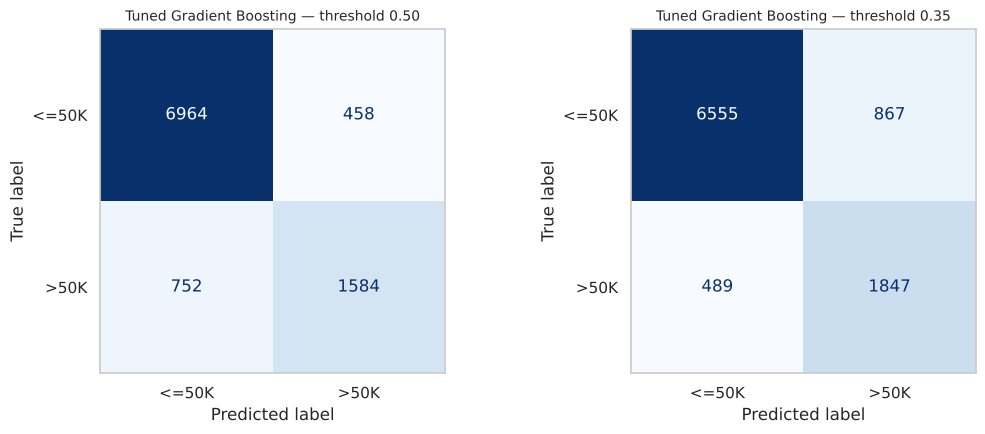

Classification report — tuned Gradient Boosting, threshold 0.35:

              precision    recall  f1-score   support

       <=50K     0.9306    0.8832    0.9063      7422
        >50K     0.6805    0.7907    0.7315      2336

    accuracy                         0.8610      9758
   macro avg     0.8056    0.8369    0.8189      9758
weighted avg     0.8707    0.8610    0.8644      9758



In [44]:
from sklearn.metrics import classification_report

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, p) in zip(axes, [('threshold 0.50', tuned_preds), (f'threshold {best_threshold:.2f}', thr_preds)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=['<=50K', '>50K']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Tuned {FINAL_MODEL} — {title}', fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.savefig('clf_final_confusion_matrices.png', bbox_inches='tight')
plt.show()

print(f"Classification report — tuned {FINAL_MODEL}, threshold {best_threshold:.2f}:\n")
print(classification_report(y_test, thr_preds, target_names=['<=50K', '>50K'], digits=4))

**Insight — the documented improvement:** the training-set CV curve peaks at a threshold of **0.35**. Applied once to
the test set, it raises **recall for the `>50K` class from 0.673 (baseline) / 0.678 (tuned) to 0.791** — the model now finds 79% of high
earners instead of 68%, cutting missed high earners from 764 to **489** — and the `>50K`-class F1 improves from 0.7251 to **0.7315**.
The price is more false positives (458 → 867), which lowers overall accuracy from 0.876 to 0.861. That is the right trade when missing a
positive is costlier than a false alarm (e.g. targeting a premium product); when it is not, the app lets the user switch back to 0.50.

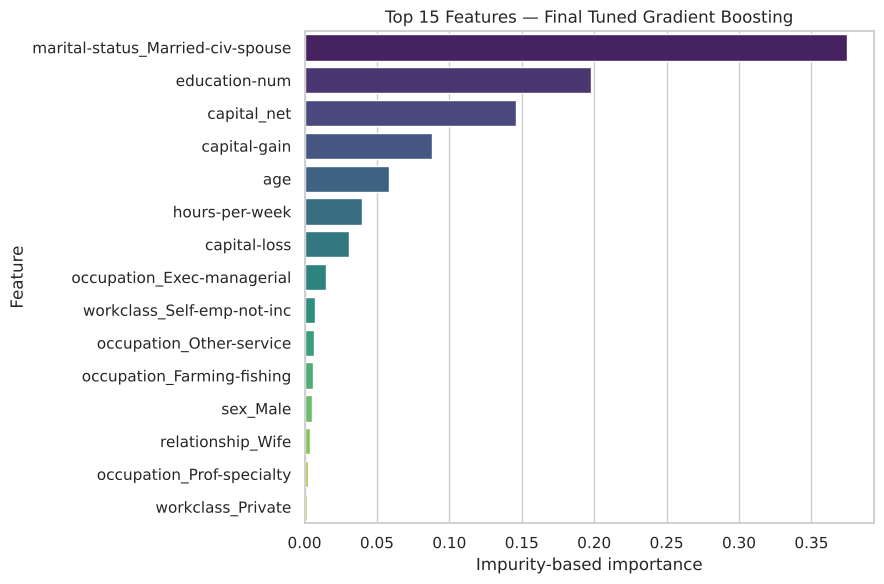

In [45]:
# What drives the final model? Impurity-based importances for tree ensembles; |coefficients| for linear / permutation otherwise.
final_est = final_pipe.named_steps['model']
final_ohe = final_pipe.named_steps['pre'].named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(CATEGORICAL_COLS)
final_feat_names = list(final_ohe) + NUMERIC_COLS
if hasattr(final_est, 'feature_importances_'):
    imp_values, imp_label = final_est.feature_importances_, 'Impurity-based importance'
elif hasattr(final_est, 'coef_'):
    imp_values, imp_label = np.abs(final_est.coef_[0]), '|coefficient|'
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(final_pipe, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring='f1_weighted', n_jobs=-1)
    imp_values, imp_label, final_feat_names = pi.importances_mean, 'Permutation importance', list(X_test.columns)

final_imp = (pd.DataFrame({'feature': final_feat_names, 'importance': imp_values})
               .sort_values('importance', ascending=False).head(15))
plt.figure(figsize=(9, 6))
sns.barplot(data=final_imp, x='importance', y='feature', hue='feature', palette='viridis', legend=False)
plt.title(f'Top 15 Features — Final Tuned {FINAL_MODEL}')
plt.xlabel(imp_label); plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('clf_final_feature_importance.png', bbox_inches='tight')
plt.show()

**Insight:** The final model leans even harder than Random Forest on a few features: `Married-civ-spouse` alone accounts
for ~37% of the total importance, followed by `education-num` (~20%), `capital_net` (~15%), `capital-gain`, `age` and `hours-per-week`.
Boosting builds each tree on the errors of the previous ones, so it concentrates on the splits that matter most, whereas Random Forest
spreads importance across many correlated features. `sex_Male` and race dummies carry very little weight once marital status, education
and occupation are known — though they are not zero, which is why the app shows a fairness caveat.

## Section H — Saving the Final Model for the Web App
The full tuned `Pipeline` (imputer → one-hot encoder → scaler → model) is saved with `joblib`, together with a small JSON file holding
everything the app needs to build a valid input row: the category options seen in training, the `hours-per-week` clipping bounds
(computed on the training split in Section B) and the CV-selected decision threshold. The final 10-model table (+ the tuned model) is
saved as CSV so the app's leaderboard always shows the same numbers as this notebook.

In [46]:
import os, json, joblib

MODELS_DIR = '../models'
os.makedirs(MODELS_DIR, exist_ok=True)

model_path = f'{MODELS_DIR}/income_classifier.joblib'
joblib.dump(final_pipe, model_path, compress=3)
print(f"Saved {model_path}  ({os.path.getsize(model_path)/1e6:.1f} MB)")

export_df = all_results_df.copy()
tuned_row = {'Model': f'{FINAL_MODEL} (tuned)', 'Part': 'Final', **{k: tuned_scores[k] for k in metric_cols},
             'Train time (s)': np.nan}
export_df = pd.concat([pd.DataFrame([tuned_row]), export_df], ignore_index=True)
export_df.to_csv(f'{MODELS_DIR}/classification_results.csv', index=False)

clf_meta = {
    'model_name': f'{FINAL_MODEL} (tuned)',
    'best_params': {k.replace('model__', ''): (v if not isinstance(v, tuple) else list(v)) for k, v in final_search.best_params_.items()},
    'threshold': best_threshold,
    'metrics_default_threshold': {k: round(float(v), 4) for k, v in tuned_scores.items()},
    'metrics_tuned_threshold': {k: round(float(v), 4) for k, v in thr_scores.items()},
    'numeric_cols': NUMERIC_COLS,
    'categorical_cols': CATEGORICAL_COLS,
    'category_options': {c: sorted(X_train[c].dropna().unique().tolist()) for c in CATEGORICAL_COLS},
    'category_modes': {c: X_train[c].mode()[0] for c in CATEGORICAL_COLS},
    'numeric_ranges': {c: [float(X_train[c].min()), float(X_train[c].max()), float(X_train[c].median())]
                       for c in ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']},
    'hours_clip': [float(lo), float(hi)],
    'education_map': (df[['education', 'education-num']].drop_duplicates().sort_values('education-num')
                        .set_index('education-num')['education'].to_dict()),
    'feature_importance': final_imp.round(5).to_dict(orient='list'),
    'confusion_matrix': confusion_matrix(y_test, thr_preds).tolist(),
    'class_balance': y.value_counts(normalize=True).round(4).to_dict(),
    'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
}
with open(f'{MODELS_DIR}/classification_meta.json', 'w') as f:
    json.dump(clf_meta, f, indent=2, default=str)
print("Saved classification_results.csv and classification_meta.json")

Saved ../models/income_classifier.joblib  (0.2 MB)
Saved classification_results.csv and classification_meta.json


## Section I — Summary

- **Part B implemented:** Random Forest, AdaBoost, Gradient Boosting, Bagging (Decision-Tree base) and MLP were trained on the identical
  stratified split and preprocessing as Part A, each with its key hyperparameter chosen by 3-fold CV on the training set.
- **Consolidated comparison:** a single 10-algorithm table reports Accuracy, weighted Precision/Recall/F1 and ROC-AUC (plus training
  time); ROC curves and confusion matrices cover all ten.
- **Best model — Gradient Boosting:** best on all five metrics (F1 0.8745, AUC 0.9318) and in 5-fold CV (0.8671 ± 0.0061).
- **Tuning:** `RandomizedSearchCV` improved CV F1 (+0.0027 on identical folds) and test ROC-AUC (0.9326); a CV-chosen decision threshold
  of 0.35 raised recall for high earners from 0.678 to 0.791 and `>50K` F1 to 0.7315.
- **Key drivers:** marital status, education, net capital gains, age and hours worked.
- **Deployment:** the tuned pipeline (`models/income_classifier.joblib`, 0.2 MB) powers the app's Income Classifier page.